In [47]:
import numpy as np
import matplotlib.pyplot as plt

In [48]:
def N1_M1(x_fp, theta_fp, a):
    a0,a1,a3,a4 = a
    return (a0+a1*x_fp) + (a3+a4*x_fp)*theta_fp
def N2_M1(x_fp, theta_fp, a):
    a0,a1,a2,a3,a4,a5 = a
    return (a0+a1*x_fp) + (a3+a4*x_fp)*theta_fp + (a2+a5*x_fp)*theta_fp**2
def N3_M1(x_fp, theta_fp, a):
    a0,a1,a3,a4,a6,a7,a9,a10 = a
    return (a0+a1*x_fp) + (a3+a4*x_fp)*theta_fp + (a6+a7*x_fp)*theta_fp**2 + (a9+a10*x_fp)*theta_fp**3
def N4_M1(x_fp, theta_fp, a):
    a0,a1,a2,a3,a4,a5,a6,a7,a9,a10 = a
    return (a0+a1*x_fp) + (a3+a4*x_fp)*theta_fp + (a6+a7*x_fp)*theta_fp**2 + (a9+a10*x_fp)*theta_fp**3 + (a2+a5*x_fp)*theta_fp**4

In [49]:
def N1_M2(x_fp, theta_fp, a):
    a0,a1,a2,a3,a4,a5 = a
    return (a0+a1*x_fp+a2*x_fp**2) + (a3+a4*x_fp+a5*x_fp**2)*theta_fp
def N1_M3(x_fp, theta_fp, a):
    a0,a1,a2,a3,a4,a5,a6,a7 = a
    return (a0+a1*x_fp+a2*x_fp**2+a6*x_fp**3) + (a3+a4*x_fp+a5*x_fp+a7*x_fp**3)*theta_fp
def N1_M4(x_fp, theta_fp, a):
    a0,a1,a2,a3,a4,a5,a6,a7,a8,a9 = a
    return (a0+a1*x_fp+a2*x_fp**2+a6*x_fp**3+a8*x_fp**4) + (a3+a4*x_fp+a5*x_fp+a7*x_fp**3+a9*x_fp**4)*theta_fp

In [69]:
data = np.loadtxt('thtg-xfp-thfp.dat')
thtg = []
xfp = []
thfp = []
for vrstica in data:
    thtg.append(vrstica[0])
    xfp.append(vrstica[1])
    thfp.append(vrstica[2])
thtg = np.array(np.deg2rad(thtg)) #deg -> rad
xfp = np.array(xfp) #mm
thfp = np.array(np.deg2rad(thfp)) #deg -> rad
d_xfp = np.array([0.001 for i in xfp]) #mili rad
d_thfp = np.array([1 for i in thfp]) #mm

In [51]:
# spreminjamo red theta - N, M=1
X = np.column_stack((xfp, thfp))
design_matrix = np.column_stack((np.ones_like(xfp), xfp, thfp, xfp * thfp))
a11, _, _, _ = np.linalg.lstsq(design_matrix, thtg, rcond=None)

X = np.column_stack((xfp, thfp))
design_matrix = np.column_stack((np.ones_like(xfp), xfp, thfp, xfp * thfp, thfp**2, xfp * thfp**2))
a21, _, _, _ = np.linalg.lstsq(design_matrix, thtg, rcond=None)

X = np.column_stack((xfp, thfp))
design_matrix = np.column_stack((np.ones_like(xfp), xfp, thfp, xfp * thfp, thfp**2, xfp * thfp**2, thfp**3, xfp * thfp**3))
a31, _, _, _ = np.linalg.lstsq(design_matrix, thtg, rcond=None)

X = np.column_stack((xfp, thfp))
design_matrix = np.column_stack((np.ones_like(xfp), xfp, thfp, xfp * thfp, thfp**2, xfp * thfp**2, thfp**3, xfp * thfp**3, thfp**4, xfp * thfp**4))
a41, _, _, _ = np.linalg.lstsq(design_matrix, thtg, rcond=None)

In [52]:
# spreminjamo red x - M, N=1
X = np.column_stack((xfp, thfp))
design_matrix = np.column_stack((np.ones_like(xfp), xfp, xfp ** 2, thfp, xfp * thfp, xfp ** 2 * thfp))
a12, _, _, _ = np.linalg.lstsq(design_matrix, thtg, rcond=None)

X = np.column_stack((xfp, thfp))
design_matrix = np.column_stack((np.ones_like(xfp), xfp, xfp ** 2, xfp ** 3, thfp, xfp * thfp, xfp ** 2 * thfp, xfp ** 3 *thfp))
a13, _, _, _ = np.linalg.lstsq(design_matrix, thtg, rcond=None)

X = np.column_stack((xfp, thfp))
design_matrix = np.column_stack((np.ones_like(xfp), xfp, xfp ** 2, xfp ** 3, xfp ** 4, thfp, xfp * thfp, xfp ** 2 * thfp, xfp ** 3 * thfp, xfp ** 4 *thfp))
a14, _, _, _ = np.linalg.lstsq(design_matrix, thtg, rcond=None)

Text(0, 0.5, '$\\theta_{tg}$')

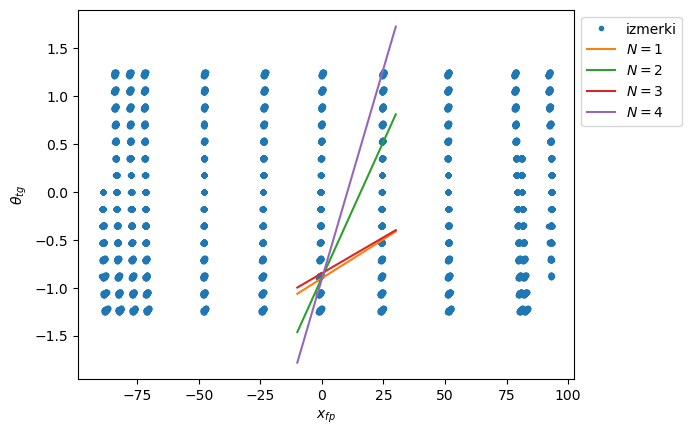

In [63]:
# M = 1 konst.
x = np.linspace(-10, 30, 100)
theta = np.array([1 for i in x])
plt.plot(xfp, thtg, '.', label='izmerki')
plt.plot(x, N1_M1(x, theta, a11), label=f'$N = 1$')
plt.plot(x, N2_M1(x, theta, a21), label=f'$N = 2$')
plt.plot(x, N3_M1(x, theta, a31), label=f'$N = 3$')
plt.plot(x, N4_M1(x, theta, a41), label=f'$N = 4$')
plt.xlabel('$x_{fp}$')
plt.legend(bbox_to_anchor=(1,1))
plt.ylabel('$\\theta_{tg}$')
#plt.savefig('slike/spektro_red_theta.pdf', bbox_inches='tight')

Text(0, 0.5, '$\\theta_{tg}$')

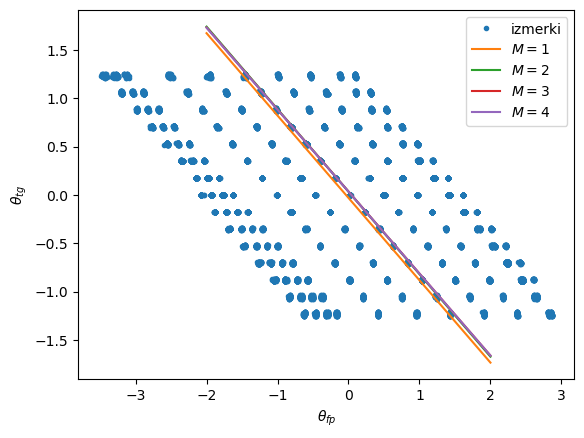

In [58]:
# N = 1 konst.
theta = np.linspace(-2, 2, 100)
x = np.array([1 for i in theta])
plt.plot(thfp, thtg, '.', label='izmerki')
plt.plot(theta, N1_M1(x, theta, a11), label='$M=1$')
plt.plot(theta, N1_M2(x, theta, a12), label='$M=2$')
plt.plot(theta, N1_M3(x, theta, a13), label='$M=3$')
plt.plot(theta, N1_M4(x, theta, a14), label='$M=4$')
plt.xlabel('$\\theta_{fp}$')
plt.legend(bbox_to_anchor=(1,1))
plt.ylabel('$\\theta_{tg}$')
#plt.savefig('slike/xxxxx.pdf', bbox_inches='tight')

TEST najboljšega modela

In [110]:
chi = []

In [111]:
def model(x_fp, theta_fp, a):
    a0,a1,a2,a3,a4,a5 = a
    return (a0+a1*x_fp+a2*x_fp**2) + (a3+a4*x_fp+a5*x_fp**2)*theta_fp
def model_1(x_fp, theta_fp, a):
    a0,a1,a2,a3,a4 = a
    return (a0+a1*x_fp+a2*x_fp**2) + (a3+a4*x_fp)*theta_fp
def model_2(x_fp, theta_fp, a):
    a0,a1,a2,a3 = a
    return (a0+a1*x_fp+a2*x_fp**2) + (a3)*theta_fp
def model_3(x_fp, theta_fp, a):
    a0,a1,a2 = a
    return (a0+a1*x_fp+a2*x_fp**2)

In [141]:
X = np.column_stack((xfp, thfp))
design_matrix = np.column_stack((np.ones_like(xfp), xfp, xfp ** 2, thfp, xfp * thfp, xfp ** 2 * thfp))
#design_matrix = np.column_stack((np.ones_like(xfp), xfp, xfp ** 2, thfp, xfp * thfp)) #model1
#design_matrix = np.column_stack((np.ones_like(xfp), xfp, xfp ** 2, thfp)) #model2
#design_matrix = np.column_stack((np.ones_like(xfp), xfp, xfp ** 2)) #model3
a, residuals, rank, singular_values = np.linalg.lstsq(design_matrix, thtg, rcond=None)

In [143]:
for i in range(len(a)):
    print(f' a_{i} = {round(a[i], 8)}, eigenvalue = {round(singular_values[i], 3)}')

 a_0 = 0.01658023, eigenvalue = 982829.523
 a_1 = 0.01713397, eigenvalue = 542351.693
 a_2 = -3.194e-05, eigenvalue = 5944.504
 a_3 = -0.85374365, eigenvalue = 3623.807
 a_4 = -8.63e-06, eigenvalue = 65.971
 a_5 = 1.25e-06, eigenvalue = 61.435


In [126]:
chi_ = sum(residuals) / (len(thtg)-len(a))
chi.append(chi_)
chi_

0.5510458229997748

In [127]:
chi

[0.00020085998018929928,
 0.00021747679427350694,
 0.00021793147756710396,
 0.5510458229997748]

[0.0, 8.272834672465486, 8.499202958058516, 274243.2626451745]

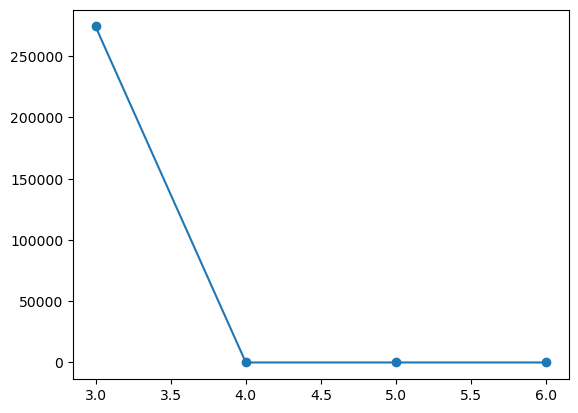

In [140]:
napaka = [(i-chi[0])/chi[0]*100 for i in chi]
plt.plot([6,5,4,3], napaka, 'o-')
napaka